# ChurnShield AI — Explainable Customer Retention & Revenue Intelligence Platform

 # Exploratory Data Analysis

## 1) IMPORT LIBRAIES

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Set graph style
sns.set_style("whitegrid")

# Show all columns
pd.set_option("display.max_columns", None)

## 2) LOAD DATASET

In [2]:
df = pd.read_csv("Telco-Customer-Churn.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [5]:
df.shape # check dataset rows and columns

(7043, 21)

In [6]:
df.info() # check column names and data types

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 3) Checking Missing Values

In [7]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
df.duplicated().sum() # check duplicate rows

np.int64(0)

In [9]:
df["customerID"].duplicated().sum() # check duplicate customer IDs

np.int64(0)

## 4) Data Cleaning

##### Convert TotalCharges into numeric format

In [10]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [11]:
df["TotalCharges"]

0         29.85
1       1889.50
2        108.15
3       1840.75
4        151.65
         ...   
7038    1990.50
7039    7362.90
7040     346.45
7041     306.60
7042    6844.50
Name: TotalCharges, Length: 7043, dtype: float64

#### check rows with missing TotalCharges

In [12]:
print("Missing TotalCharges:")
df[df["TotalCharges"].isnull()][["tenure", "MonthlyCharges"]]

Missing TotalCharges:


,tenure,MonthlyCharges
488,0,52.55
753,0,20.25
936,0,80.85
1082,0,25.75
1340,0,56.05
3331,0,19.85
3826,0,25.35
4380,0,20.00
5218,0,19.70
6670,0,73.35


#### Replace missing TotalCharges with 0
#### These customers have zero tenure

In [13]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

###  Remove customerID column

In [14]:
df = df.drop("customerID", axis=1)

In [15]:
print("shape after cleaning:", df.shape)

shape after cleaning: (7043, 20)


# 5) FEATURE ENGINEERING 

##### Convert SeniorCitizen values into Yes and No

In [16]:
df["SeniorCitizen"] = df["SeniorCitizen"].map({
    0: "No",
    1: "Yes"
})

In [17]:
df["SeniorCitizen"].head()

0    No
1    No
2    No
3    No
4    No
Name: SeniorCitizen, dtype: object

##### Convert Churn into numerical values
##### Yes = 1, No = 0

In [18]:
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

In [19]:
df["ChurnFlag"].head()

0    0
1    0
2    1
3    0
4    1
Name: ChurnFlag, dtype: int64

### Create tenure groups

In [20]:
df["tenure_group"] = pd.cut(df["tenure"],bins=[-1, 12, 24, 48, 72],
   labels=["0-12", "13-24", "25-48", "49-72"])

In [21]:
df["tenure_group"].head()

0     0-12
1    25-48
2     0-12
3    25-48
4     0-12
Name: tenure_group, dtype: category
Categories (4, object): ['0-12' < '13-24' < '25-48' < '49-72']

In [22]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChurnFlag,tenure_group
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0,0-12
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0,25-48
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,0-12
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0,25-48
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,0-12


# 6) STATISTICAL SUMMARY

#### Basic statistical inforamation

In [23]:
print ("Statistical Summary:")
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(2)

Statistical Summary:


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


#### Check skewness

In [24]:
print("Skewness:")
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(2)

Skewness:


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


# 7) OUTLIER DETECTION

In [25]:
num_cols = ["tenure","MonthlyCharges","TotalCharges"]

In [26]:
num_cols

['tenure', 'MonthlyCharges', 'TotalCharges']

In [27]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)   # Find Q1 and Q3
    Q3 = df[col].quantile(0.75)

In [28]:
IQR = Q3 - Q1 # calculate IQR

In [29]:
lower_limit = Q1 - 1.5 * IQR # Find lower and upper limits
upper_limit = Q3 + 1.5 * IQR

In [30]:
 outliers = df[(df[col] < lower_limit) | (df[col] > upper_limit)]

In [31]:
outliers

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChurnFlag,tenure_group


In [32]:
print(col, "Outliers:", len(outliers))

TotalCharges Outliers: 0


# 8) TARGET DISTRIBUTION

#### Count customers who left and stayed

In [33]:
print("Churn Distribution:")
df["Churn"].value_counts()

Churn Distribution:


Churn
No     5174
Yes    1869
Name: count, dtype: int64

### Calculate churn percentage

In [34]:
churn_rate = df["ChurnFlag"].mean() * 100

In [35]:
print("Churn Rate:", round(churn_rate, 2), "%")

Churn Rate: 26.54 %


### Visualize churn distribution

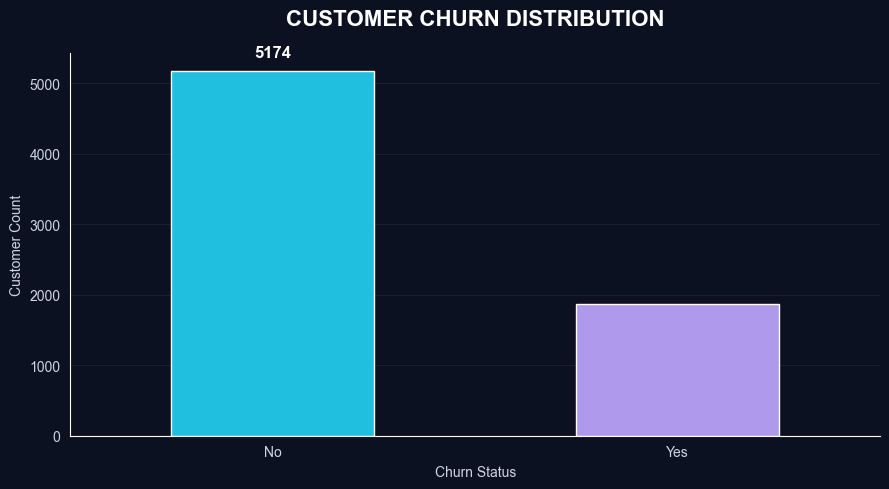

In [44]:

plt.figure(figsize=(9, 5), facecolor="#0B1120")

ax = sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette={"No": "#00D4FF", "Yes": "#A78BFA"},
    legend=False,
    width=0.5
)

ax.set_facecolor("#0B1120")

ax.bar_label(
    ax.containers[0],
    fmt="%d",
    padding=8,
    color="white",
    fontsize=12,
    fontweight="bold"
)

ax.set_title(
    "CUSTOMER CHURN DISTRIBUTION",
    color="white",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Churn Status", color="#CBD5E1")
ax.set_ylabel("Customer Count", color="#CBD5E1")

ax.tick_params(colors="#CBD5E1")
ax.grid(axis="y", color="#334155", alpha=0.35)
ax.set_axisbelow(True)

sns.despine()
plt.tight_layout()
plt.show()


# 9) CATEGORICAL FEATURES VS CHURN

In [47]:
cat_cols = df.select_dtypes(include="object").columns.drop("Churn")

In [48]:
print("Categorical Columns:")
print(cat_cols)

Categorical Columns:
Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod'],
      dtype='object')


####  Check churn percentage for important features

In [49]:
features = ["Contract","InternetService","PaymentMethod","SeniorCitizen","Partner","TechSupport","OnlineSecurity"]

In [50]:
for col in features:
     churn_percentage = (df.groupby(col)["ChurnFlag"].mean() * 100)

In [51]:
print("\nChurn Rate by", col)
print(churn_percentage.round(2))


Churn Rate by OnlineSecurity
OnlineSecurity
No                     41.77
No internet service     7.40
Yes                    14.61
Name: ChurnFlag, dtype: float64


# 10. CHI-SQUARE TEST

In [52]:
from scipy.stats import chi2_contingency
for col in cat_cols:
    table = pd.crosstab(df[col], df["Churn"])
    chi2, p_value, dof, expected = chi2_contingency(table)

In [53]:
print("\nFeature:", col)
print("P-value:", round(p_value, 5))


Feature: PaymentMethod
P-value: 0.0


In [54]:
if p_value < 0.05:
    print("Significant relationship with Churn")
else:
    print("No significant relationship with Churn")
    

Significant relationship with Churn
